# Практика 08-10-2026

## Парадокс дня рождения

In [5]:
import pandas as pd
import numpy as np

bd = pd.Series(range(1, 366))
group = bd.sample(23, replace=True)
group.duplicated()

group

318    319
343    344
287    288
187    188
97      98
113    114
222    223
306    307
51      52
21      22
189    190
336    337
70      71
17      18
201    202
324    325
38      39
150    151
330    331
285    286
357    358
321    322
329    330
dtype: int64

In [6]:
print(*group[group.duplicated() == True].values)

In [8]:
group.nunique()

23

In [11]:
rooms = [bd.sample(23, replace=True).duplicated().max() for _ in range(10_000)]

In [13]:
np.mean(rooms)

np.float64(0.508)

In [14]:
rooms = [bd.sample(50, replace=True).duplicated().max() for _ in range(10_000)]
np.mean(rooms)

np.float64(0.9687)

In [20]:
from math import factorial as f

n = 40

f(365) / ((365 ** n) * f(365 - n))

0.10876819018205101

### №3.26

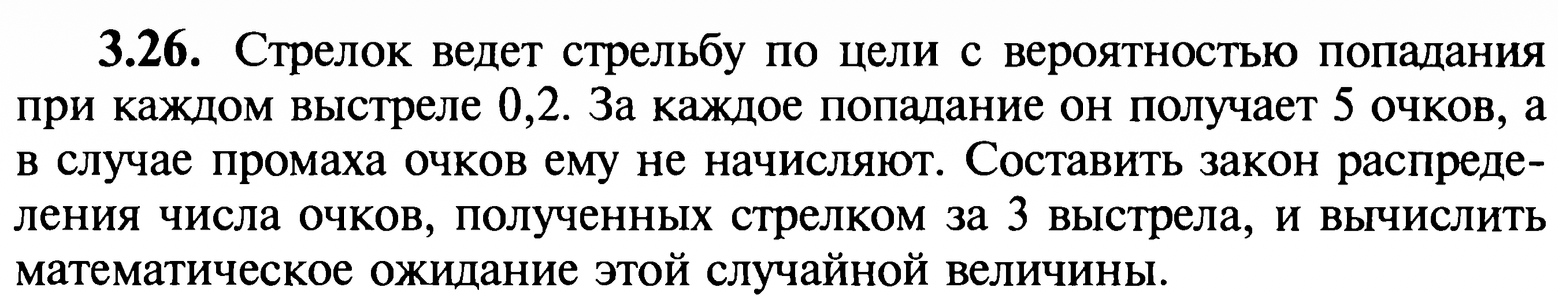

Рассмотрим СВХ – числа очков, полученных стрелком за $3$ выстрела

$Y$ - число попаданий


СВ $Y$ распредлена по схеме Бернулли

- $P(X = 0) = P_{3}(Y = 0) = C_{3}^{0} \cdot 0.2^0 \cdot 0.8^3 = $
- $P(X = 5) = P_{3}(Y = 1) = C_{3}^{1} \cdot 0.2^1 \cdot 0.8^2 = $
- $P(X = 10) = P_{3}(Y = 2) = C_{3}^{2} \cdot 0.2^2 \cdot 0.8^1 = $
- $P(X = 15) = P_{3}(Y = 3) = C_{3}^{3} \cdot 0.2^3 \cdot 0.8^0 = $

$$
\begin{array}{|c|c|c|c|c|}
\hline
№ & 0 & 1 & 2 & 3 \\
\hline
x_i & 0 & 5 & 10 & 15 \\
\hline
p_i & 0.512 & 0.384 & 0.096 & 0.008\\
\hline
\end{array}
$$

$\sum{p_i} = 1$

In [37]:
from scipy.stats import binom

n = 3
p = 0.2
m = 0
x_i = 0
result = 0

for m in range(0, n + 1):
    p_i = round(binom.pmf(m, n, p), 4)
    print(x_i, p_i)
    result += (x_i * p_i)
    x_i += 5
print(f'Мат. ожидание: {result}')

0 0.512
5 0.384
10 0.096
15 0.008
Мат. ожидание: 3.0


$$E(X) = \sum\limits_{i = 0}^{3}{x_i \cdot p_i} = \boxed{8.0}$$

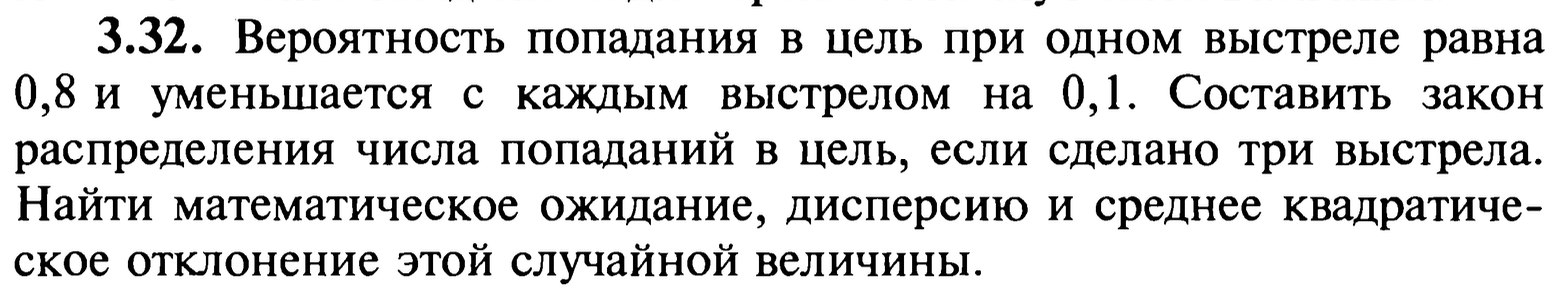


Рассмотрим СВ $X$ - число попаданий при $3$-х выстрелах

Вероятность попадания при $i$-ом выстреле:
- $p_1 = 0.8$
- $p_2 = 0.7$
- $p_3 = 0.6$

$$
\begin{array}{|c|c|c|c|c|}
\hline
x_i & 0 & 1 & 2 & 3 \\
\hline
p_i & 0.024 & 0.1880 & 0.4520 & 0.3360\\
\hline
\end{array}
$$

- $P(X = 0) = 0.2 \cdot 0.3 \cdot 0.4 = 0.024$
- $P(X = 1) = 0.8 \cdot 0.3 \cdot 0.4 + 0.2 \cdot 0.7 \cdot 0.4 + 0.2 \cdot 0.3 \cdot 0.6 = 0.1880$
- $P(X = 2) = 0.8 \cdot 0.7 \cdot 0.4 + 0.8 \cdot 0.3 \cdot 0.6 + 0.2 \cdot 0.7 \cdot 0.6 = 0.4520$
- $P(X = 3) = 0.8 \cdot 0.7 \cdot 0.6 = 0.3360$


Проверка: $\sum{p_i} = 1$

In [42]:
from scipy.stats import binom

probabilities = [
    0.0024,
    0.1880,
    0.4520,
    0.3360
]
E = 0
for i in range(0, 4):
    E += probabilities[i] * i
print(f'Мат. ожидание E = {E}')

Мат. ожидание E = 2.1


Дз разобрать решение задач №3.18-3.23